<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/Reading_digit_with_SKlearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [69]:
# 2. Data Loading
# For Colab:

import io
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded["digit.csv"]), header=None)

# If running locally, use:
#df = pd.read_csv("digit.csv", header=None)


Saving digit.csv to digit.csv


In [70]:
 #3. Quick Data Inspection
print("Shape:", df.shape)
print("First few rows:\n", df.head())

Shape: (500, 785)
First few rows:
    0    1    2    3    4    5    6    7    8    9    ...  775  776  777  778  \
0    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
1    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
2    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
3    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   
4    0    0    0    0    0    0    0    0    0    0  ...    0    0    0    0   

   779  780  781  782  783  784  
0    0    0    0    0    0    0  
1    0    0    0    0    0    0  
2    0    0    0    0    0    0  
3    0    0    0    0    0    0  
4    0    0    0    0    0    0  

[5 rows x 785 columns]


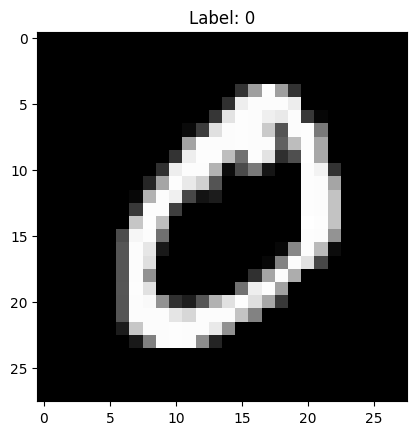

In [105]:
# 4. Visualize a Sample Digit
first_digit = np.array(df.iloc[0, :-1]).reshape(28, 28)
# Turns pandas data into array
#unidimensional of Numpy, gets the first element and does a 28x28 matrix
plt.imshow(first_digit, cmap="gray") #Interprets matrix as photo
plt.title(f"Label: {df.iloc[0, -1]}") #Graphic title using formated table
plt.show() #display the figure clean


In [72]:
# 5. Reshape for Further Analysis (optional)
# For access as [digit][sample][features] if needed
digit_images = np.array(df.iloc[:, :-1]).reshape(-1, 28, 28)
#Gets all the images, Pandas data to unidimensional array and
#then reshaped to 28x28 bidimensional function

In [73]:
# 6. Binarize Images (thresholding)
bin_digits = (df.iloc[:, :-1] > 128).astype(int)
#Binarize dataframes, selects all columns except last one (they are the images real values)
#and asigns them values 0 to 1 depending if the value is superior to 128 in that matrix cell


In [74]:
# 7. Prepare Data dataframe --> values
X = bin_digits.values #Binarized image values
y = df.iloc[:, -1].values #Real values of the images
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #Splits



In [75]:
# 8. Train Multinomial Naive Bayes Model
model_mn = MultinomialNB().fit(X_train, y_train) #Train the model. MultinomialNB
#Designed for discrete data, specifically counts or frequencies (non-negative integer values).

#1. Groups images by class, with the objective (y_train).

#2. Calculates the probability of each digit to calculate class frequency.

#3. Adds the intensity from each pixel per digit.

#4. Calculates the conditional probabilities.P(Xi|y=k) →Each specific pixel, digit k

#5. Stores the probability matrices.


In [76]:
# 9. Show Test prediction and compare with the actual value
y_pred=model_mn.predict(X_test) #Predict with the model the value of x_test
print("Prediction and Actual value" )
np.array([y_pred ,y_test]).T
#Make a comparation matrix of the real value and the predicted one

Prediction and Actual value


array([[7, 7],
       [1, 1],
       [7, 7],
       [3, 3],
       [2, 2],
       [7, 7],
       [7, 7],
       [2, 2],
       [1, 1],
       [9, 9],
       [0, 0],
       [0, 3],
       [8, 8],
       [1, 1],
       [9, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [9, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [9, 9],
       [4, 4],
       [2, 2],
       [6, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [8, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [9, 7],
       [1, 1],
       [9, 9],
       [3, 3],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [3, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [5, 1],
       [1, 2],
       [0, 0],
       [5, 4],
       [1, 1],
       [9, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [77]:
# 10. Compare the probability
np.set_printoptions(precision=5,suppress=True) #Optional fixes, only 5 decimals per digit at max
y_prob = model_mn.predict_proba(X_test) #Predicts the values of X_test, but in a 10x100 matrix,
# showind the probabilities of each photo for each digit
print(y_prob)

[[0.      0.      0.      0.      0.      0.      0.      1.      0.      0.     ]
 [0.      1.      0.      0.      0.      0.      0.      0.      0.      0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.     ]
 [0.      0.      0.      0.99997 0.      0.00003 0.      0.      0.      0.     ]
 [0.      0.01049 0.9814  0.00812 0.      0.      0.      0.      0.      0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.     ]
 [0.      0.      1.      0.      0.      0.      0.      0.      0.      0.     ]
 [0.      0.99999 0.      0.      0.      0.      0.      0.      0.00001 0.     ]
 [0.      0.      0.      0.      0.      0.      0.      0.      0.      1.     ]
 [1.      0.      0.      0.      0.      0.      0.      0.      0.      0.     ]
 [0.46223 0.      0.41017 0.00408 0.      0.12352 0.      0.      0.      0.     ]
 [0.

In [78]:
# Show the result with probability
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
Result=np.hstack((y_prob, y_pred.reshape(-1, 1)))
#Combination of both before, shows the probability and also the predicted value
print(Result)

[[0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      1.      0.      0.      0.      0.      0.      0.      0.      0.      1.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      0.      0.99997 0.      0.00003 0.      0.      0.      0.      3.     ]
 [0.      0.01049 0.9814  0.00812 0.      0.      0.      0.      0.      0.      2.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      0.      0.      0.      0.      0.      1.      0.      0.      7.     ]
 [0.      0.      1.      0.      0.      0.      0.      0.      0.      0.      2.     ]
 [0.      0.99999 0.      0.      0.      0.      0.      0.      0.00001 0.      1.     ]
 [0.      0.      0.      0.      0.      0.      0.      0.      0.      1.      9.     ]
 [1.      0.      0.      0.      0.      0.      0.      0.      0.      0.      0.     ]

In [79]:
# 11. Count the mislabeled
print("Number of mislabeled points out of a total %d points " , (y_test != y_pred).sum())
#Sumatory of all the values that dont match

print("The accuracy is %.2f"%((y_test == y_pred).mean()*100) +"%" ) #Total accuracy


Number of mislabeled points out of a total %d points  12
The accuracy is 88.00%


In [80]:
# 12. Use score to find the accuracy
print("MultinomialNB train accuracy:", model_mn.score(X_train, y_train)) #Train accuracy
print("MultinomialNB test accuracy:", model_mn.score(X_test, y_test)) #Test accuracy

MultinomialNB train accuracy: 0.86
MultinomialNB test accuracy: 0.88


In [81]:
# 13. Some parameters

print(model_mn.classes_) #detected classes
print(model_mn.class_count_) #nº of images per class
#print(model_mn.class_prior_) NOT AVAILABLE IN MULTINOMIAL
print(model_mn.feature_count_) #arrays of probability of each number
print(model_mn.feature_log_prob_) #probability in logaritmical scale

[0 1 2 3 4 5 6 7 8 9]
[39. 33. 45. 41. 46. 44. 38. 38. 41. 35.]
[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  3.  9.  9. 10. 13. 13.  9.  3.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  3.  3. 10. 15. 23. 28. 30. 29. 27. 20. 15.  9.  2.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  4.  6. 13. 14. 23. 27. 32. 36. 35. 30. 31. 20. 15.  8.  1.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  3.  6.  9. 12. 22. 26. 34. 32. 32. 33. 34. 32. 28. 21. 12.  4.  3.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  2.  5.  9. 11

Referece: https://scikit-learn.org/stable/modules/naive_bayes.html


In [82]:
# 14. Create a confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=model_mn.classes_)
#Creation of the confusion matrix with test values
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_mn.classes_)
#Visualizes the confusion matrix

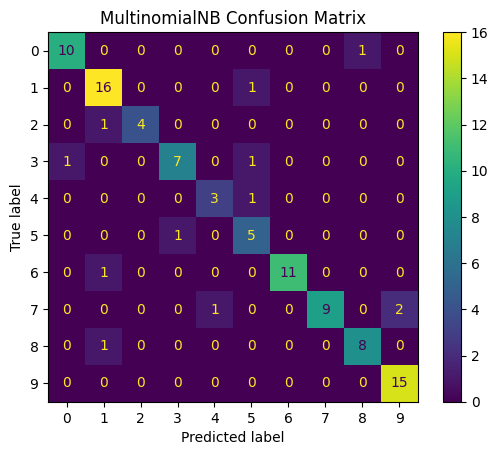

In [83]:
disp.plot()
plt.title("MultinomialNB Confusion Matrix")
plt.show()

Reference:https://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html


# Gaussian Navie Bayes

In [84]:
# 1. Train Gaussian Naive Bayes Model
model_gb = GaussianNB().fit(X_train, y_train)
y_pred2 =model_gb.predict(X_test)
np.array([y_pred2, y_test]).T #The same as before


array([[9, 7],
       [1, 1],
       [9, 7],
       [3, 3],
       [2, 2],
       [7, 7],
       [9, 7],
       [2, 2],
       [8, 1],
       [9, 9],
       [0, 0],
       [0, 3],
       [8, 8],
       [1, 1],
       [9, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [4, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [4, 9],
       [4, 4],
       [2, 2],
       [6, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [8, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [7, 7],
       [1, 1],
       [8, 9],
       [2, 3],
       [0, 0],
       [8, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [2, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [5, 1],
       [1, 2],
       [0, 0],
       [4, 4],
       [8, 1],
       [8, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [85]:
# 2. Show output parameters

np.set_printoptions(precision=5,suppress=True)
y_prob = model_gb.predict_proba(X_test)
print(y_prob)
result = np.hstack((y_prob, y_test.reshape(-1, 1)))
print(result)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0.

In [86]:
#3 Task 1. Compare the prediction output and the real test data
print("Accuracy: ",((y_test == y_pred2).mean() *100) , "%")

Accuracy:  76.0 %


In [87]:
#3 Task 2. Compare and find mislabelled data
mislabeled = (y_test != y_pred2).sum()
total = len(y_test)
print("Bad clasiffied:", mislabeled, "of",total)

Bad clasiffied: 24 of 100


In [88]:
#4 Task 3. Compute the score of both train/test
train_score = model_gb.score(X_train, y_train)
test_score  = model_gb.score(X_test, y_test)

print("Train Accuracy Score:" , train_score)
print("Test Accuracy Score:  ",test_score)

Train Accuracy Score: 0.855
Test Accuracy Score:   0.76


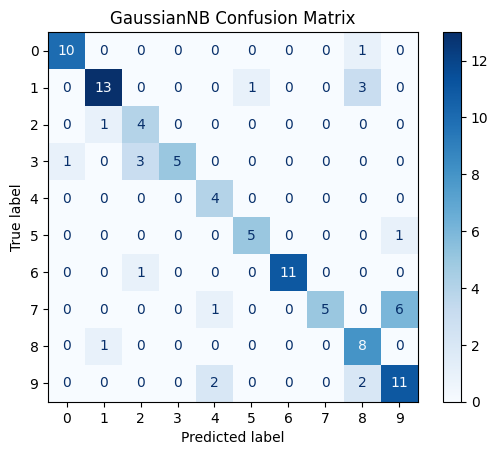

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cmd = confusion_matrix(y_test, y_pred2, labels=model_mn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cmd, display_labels=model_mn.classes_)
disp.plot(cmap ="Blues")
plt.title("GaussianNB Confusion Matrix")
plt.show()

In [90]:
# Use score to find the accuracy
print("Bayes train accuracy:", model_gb.score(X_train, y_train))
print("Bayes test accuracy:", model_gb.score(X_test, y_test))

Bayes train accuracy: 0.855
Bayes test accuracy: 0.76


In [108]:
#5 Task 4. Computer Precision of all data (How it can be done? Explain the result)
tp = np.diag(cmd) #Obtains the elements of the diagonal
pred_per_column = cmd.sum(axis=0)
print("Extracted elements from the diagonal \n",tp)
print()
print("Predicted clases \n",pred_per_column) #Added elements of the vertical
print()
precision = tp / pred_per_column
print("Real hits / Total predictions per class \n",precision) #Real hits / Total predictions per class
average_precision= precision.mean()
print()
print("Average precision of all data:", average_precision * 100 ,"%")

Extracted elements from the diagonal 
 [10 13  4  5  4  5 11  5  8 11]

Predicted clases 
 [11 15  8  5  7  6 11  5 14 18]

Real hits / Total predictions per class 
 [0.90909 0.86667 0.5     1.      0.57143 0.83333 1.      1.      0.57143 0.61111]

Average precision of all data: 78.63059163059162 %


In [92]:
#6 Task 5. Computer Recall  of all data How it can be done? Explain the result)
# Add horizontally per rows (axis=1) -> Real data per class (TP + FN)
actual_per_row = cmd.sum(axis=1)
recall = tp / actual_per_row #Calculate recall per class
average_recall = recall.mean()
print("True positives (TP):\n", tp)
print("\n Total of real data per class (Rows):\n", actual_per_row)
print("\nRecall per class:\n", recall)
print("\nAverage Recall of all data:", average_recall * 100 ,"%")


True positives (TP):
 [10 13  4  5  4  5 11  5  8 11]

 Total of real data per class (Rows):
 [11 17  5  9  4  6 12 12  9 15]

Recall per class:
 [0.90909 0.76471 0.8     0.55556 1.      0.83333 0.91667 0.41667 0.88889 0.73333]

Average Recall of all data: 78.18241235888294 %


### Explanation of Precision and Recall

Precision (per class) = TP / (TP + FP): of all images the model labelled as digit *k*, how many really were *k*.
Recall (per class) = TP / (TP + FN): of all real images of digit *k*, how many the model found.
With 10 classes, each digit is treated as the "positive" class once (one-vs-rest). All values are computed on the test set (100 images) from the GaussianNB confusion matrix. The average recall printed above (78.2 %) is the unweighted mean over the 10 classes. Weighting each class by its number of samples (average='weighted') gives a precision of 0.818 and a recall of 0.760; the weighted recall is equal to the test accuracy (0.76).
Digit 2 has the lowest precision (0.50): the model predicts "2" 8 times but only 4 are correct, mainly because 3 real 3s (and one real 6) are labelled 2 (many FP). Digits 4 and 8 follow with 0.571.
Digit 7 has the lowest recall (0.417): only 5 of the 12 real 7s are found and 6 are labelled 9 (many FN). Digit 3 is next (0.556): 3 of its 9 images are labelled 2. Digit 4 has perfect recall (1.0) but low precision, because some 7s and 9s are labelled 4.

### Comparison with the previous exercise (MultinomialNB)

| Model | Train acc. | Test acc. | Mislabeled (test, of 100) |
|---|---|---|---|
| MultinomialNB | 0.86 | 0.88 | 12 |
| GaussianNB | 0.855 | 0.76 | 24 |

Observations
GaussianNB reached a test accuracy of 0.76 compared with 0.88 for MultinomialNB, so MultinomialNB performs better (12 more correct predictions out of 100, half the errors).
Both models have almost the same train accuracy (~0.86), but GaussianNB drops about 9.5 points on the test set (0.855 → 0.76), while MultinomialNB does not drop (0.86 → 0.88). GaussianNB therefore generalizes worse (overfitting).
Most confused digits with GaussianNB: 7→9 (6 times), 3→2 (3 times), 1→8 (3 times), 9→4 and 9→8 (2 times each). With MultinomialNB the errors are fewer and more spread out: 7→9 (2 times) and several single errors.
GaussianNB assumes that each pixel follows a normal distribution per class. In this dataset 206 of the 784 pixels are always 0 (borders), and after binarization the other pixels only take the values 0 or 1, so they are not bell-shaped. The estimated variances are very small or unreliable, which makes the likelihoods extreme and the model overconfident. MultinomialNB treats the pixel value like a count, which fits this kind of data better and is more stable.

In [93]:
uploaded2 = files.upload()
df2 = pd.read_csv(io.BytesIO(uploaded2["Weight_Height_M_W.csv"]))

Saving Weight_Height_M_W.csv to Weight_Height_M_W.csv


In [94]:
#Separate each data per etiquete and train_test_split
X2 = df2[["Height", "Weight"]].values
y2 = df2["gender"].values
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)


In [95]:
priors = [0.35, 0.65]                       # in order of np.unique(y2): [M, W]
model_gender = GaussianNB(priors=priors).fit(X2_train, y2_train)#
y2_pred = model_gender.predict(X2_test)

#1. GaussianNB() (Gaussian Naive Bayes)
#Data Type: Designed for continuous (real-valued) features.
#Assumption:
#    It assumes that the continuous features associated with each class follow
#    a Gaussian (Normal) distribution (bell curve).
#How it works:
#    It calculates the mean ($\mu$) and variance ($\sigma^2$) of each feature for
#    each class to compute probabilities.
#Common Use Cases:
#    Physical measurements (e.g., height, weight, temperature).
#    Datasets where features are continuous floating-point numbers.

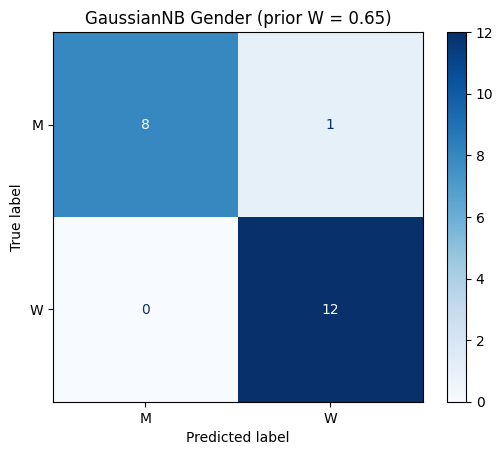

In [96]:
cm2 = confusion_matrix(y2_test, y2_pred, labels=model_gender.classes_)
disp2 = ConfusionMatrixDisplay(cm2, display_labels=model_gender.classes_)
disp2.plot(cmap="Blues")
plt.title("GaussianNB Gender (prior W = 0.65)")
plt.show()

Without custom priors (estimated from the data: M = 0.5625, W = 0.4375) the result is identical: accuracy 0.95 and the same confusion matrix [[8, 1], [0, 12]]. The prior of 0.65 does not change the predictions here because the test samples are well separated by height and weight; only borderline cases would be affected.

# Assignment 4

Continue from the previous lab (Classify with Bayesian)
(Don't forget to train test split)

→TASK1
use PCA to reduce to lower dimension +use Bayes’s approach (at least .95 )

In [97]:
from sklearn import preprocessing
# Create the standard scaler
scaler = preprocessing.StandardScaler() #Standardscaler is a prepocessing tool
# Standarize =   transform each píxel to mean 0 & deviation 1: x’ = (x − μ) / σ.
#Learns mean and deviation from train data &
# transforms (does also scaler.fit(X_train) to fit on TRAIN data only)
X_train_std = scaler.fit_transform(X_train) #Apply transformation to train data
X_test_std  = scaler.transform(X_test) #Apply transformation to test data

In [98]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
#n_components is a parameter in Scikit-Learn's Principal Component Analysis (PCA)
# that determines how many dimensions (principal components)
# you want to keep or how much variance you want your compressed data to retain.

#Orders the numbers regarding how much importance they have in the variance
#Keeps the minimun number of components to conserve the 95% of the variance
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca  = pca.transform(X_test_std) #Learns in train and transforms train and test

1. Passing an Integer (Exact Number of Components)
Example: PCA(n_components=2) or PCA(n_components=50)
What it does: Tells the algorithm to reduce your dataset down to that exact number of dimensions. For instance, if your digit images originally had 784 pixels, setting n_components=2 compresses each image into just 2 numbers (PC1 and PC2), which is useful for 2D visualization.   
2. Passing a Float between 0 and 1 (Variance Retention)
Example: PCA(0.95) or PCA(0.98)
What it does: Tells the algorithm to automatically select however many principal components are needed to preserve that fraction of the total variance in the dataset.   For example, PCA(0.98) will keep enough components so that 98% of the information/variance from the original pixels is retained, dropping the rest as noise.

In [99]:
model_pca = GaussianNB().fit(X_train_pca, y_train)
#Trains a model with the reduced data
#Calculates the proportion of hits
print("Train accuracy:", model_pca.score(X_train_pca, y_train))
print("Test accuracy :", model_pca.score(X_test_pca, y_test))

Train accuracy: 0.8925
Test accuracy : 0.76


→TASK2
Plot the first 2 Components to 2 D plot of at least 2-3 digits

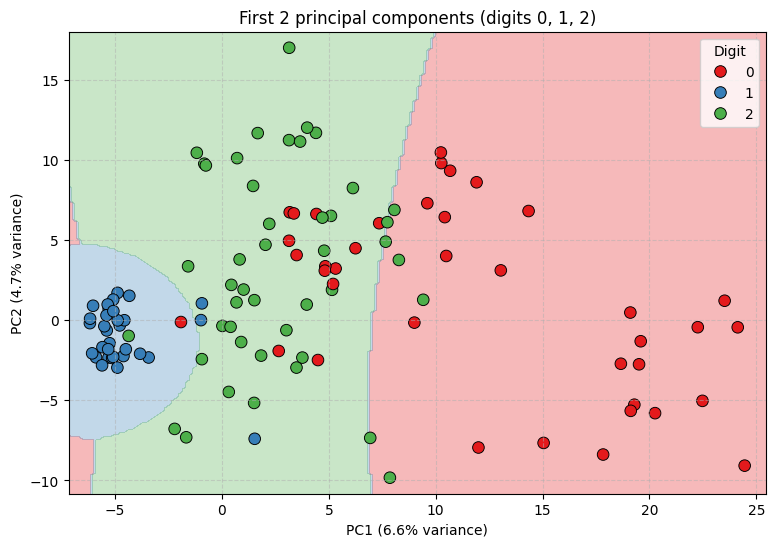

Variance explained by PC1 + PC2: 0.11289953956436101


In [100]:
import seaborn as sns

# 1. Reduce dimensionality to 2D using PCA (keeping only the top 2 principal components)
#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(X_train_std)   # learn only with train

# 2. Filter the dataset to isolate specific classes (digits 0, 1, and 2) for clear 2D plotting
# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits


X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
# 2D features for digits 0, 1, and 2
y_plot = y_train[mask] #Images from selected digits from y_train
# Corresponding labels

plt.figure(figsize=(9, 6))

# 3. Create a dense grid (meshgrid) spanning the 2D PCA space to plot decision boundaries
#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# 4. Train a Gaussian Naive Bayes classifier on the 2D projection and predict regions
g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()]) # Predict class for every point on the grid
Z = Z.reshape(xx.shape) # Reshape predictions to match the grid shape

# 5. Extract variance ratios and define a distinct color palette for the 3 classes
#Parameters to adjust
var = pca_2d.explained_variance_ratio_
cols = sns.color_palette("Set1", 3)

# Draw the colored decision boundary regions in the background
plt.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5, 2.5], colors=cols)
#Draw graphic
# 6. Overlay the actual data points as a scatter plot on top of the regions
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=[0, 1, 2], s=70, edgecolor="k")
# 7. Configure plot aesthetics (labels with variance percentages, title, and legend)
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("First 2 principal components (digits 0, 1, 2)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Print the total amount of variance captured by the first two principal components
print("Variance explained by PC1 + PC2:", var.sum())

→Task3
Plot Discrimination region (consult week 1 Assingment)

→Compare the result from the full dimension (How much reduction has it made)

Accuracy 2D (train): 0.7863247863247863


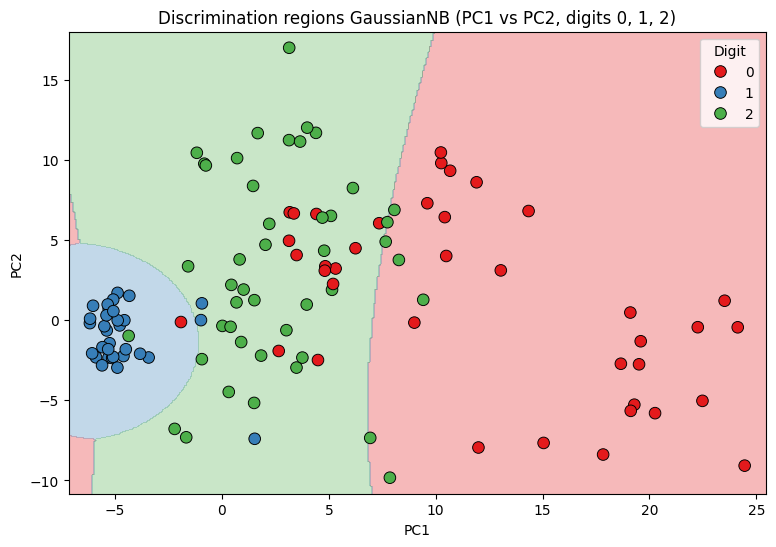

In [101]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize and train a Gaussian Naive Bayes classifier on the 2D PCA-reduced data
model_2d = GaussianNB().fit(X_plot, y_plot)

# Calculate and print the model's classification accuracy on the training data
print("Accuracy 2D (train):", model_2d.score(X_plot, y_plot))

# Determine the minimum and maximum boundaries for the 2D space, adding a padding margin of 1
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

# Generate a high-resolution 400x400 coordinate grid spanning the entire feature space
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))

# Flatten the grid coordinates, predict the class label for every point, and reshape back to the grid's shape
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Create a matplotlib figure with a specified size
plt.figure(figsize=(9, 6))

# Define a distinct 3-color palette using Seaborn for the three digit classes (0, 1, and 2)
cols = sns.color_palette("Set1", 3)

# Draw filled contour regions in the background to visualize the model's decision boundaries (with transparency alpha=0.3)
plt.contourf(xx, yy, Z, alpha=0.3, levels=[-0.5, 0.5, 1.5, 2.5], colors=cols)

# Overlay the actual data points as a scatter plot with black borders for clear visibility
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=[0, 1, 2], s=70, edgecolor="k")

# Set axis labels, title, and legend, then display the final plot
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Discrimination regions GaussianNB (PC1 vs PC2, digits 0, 1, 2)")
plt.legend(title="Digit")
plt.show()

Extra, with 10 digits, more chaotic

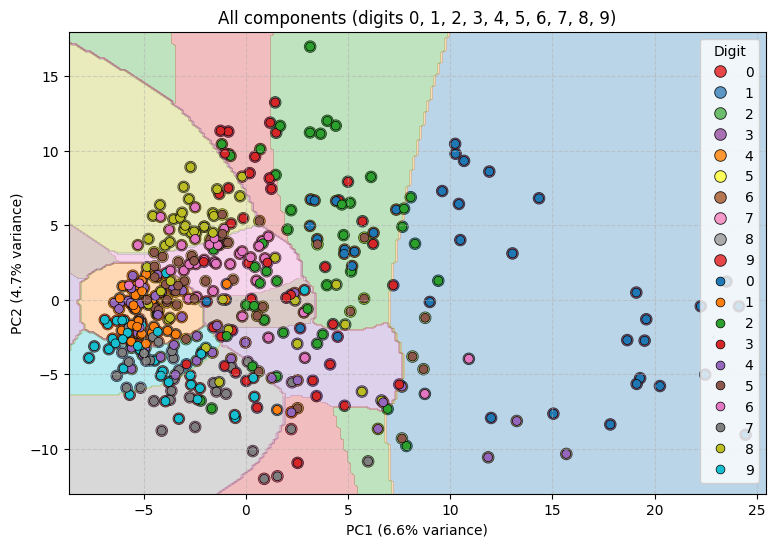

Variance explained by PC1 + PC2: 0.11289954352792442


In [102]:
import seaborn as sns

#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(X_train_std)   # learn only with train

# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
cols = sns.color_palette("tab10", 10)
plt.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(-0.5, 10.5, 1), colors=cols)
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette=cols, hue_order=list(range(10)), s=40, edgecolor="k")
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("All components (digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

Comparation

In [103]:
import time

# 1. Measure training time for the model using ALL original features
t0 = time.time()
m_full = GaussianNB().fit(X_train, y_train)
t_full = time.time() - t0

# 2. Measure training time for the model using PCA-reduced features (95% variance)
t1 = time.time()
m_95 = GaussianNB().fit(X_train_pca, y_train)
t_95 = time.time() - t1

# 3. Track feature dimensions (number of columns/pixels)
d_full = X_train.shape[1]
d_95   = pca.n_components_

# Print out the execution times for comparison
print(f"Times: \n full: {t_full:.5f} \n PCA:  {t_95:.5f}")

# Print out the dimension counts
print("Complete dimension :", d_full)
print("Dimensions with PCA   :", d_95)

# 4. Calculate and print the percentage of dimensions retained (fixed syntax from '1d_95' to 'd_95')
print(f"Retention ratio       : {(d_95 / d_full) * 100:.1f}%")

# (Optional redundancy: re-fitting m_full, though it was already trained above)
m_full = GaussianNB().fit(X_train, y_train)

# 5. Evaluate and print test accuracy for both the full-feature model and the PCA model
print("Test accuracy complete:", m_full.score(X_test, y_test))
print("Test accuracy PCA 95% :", model_pca.score(X_test_pca, y_test))

Times: 
 full: 0.01162 
 PCA:  0.00411
Complete dimension : 784
Dimensions with PCA   : 185
Reduction             : 76.4%
Test accuracy complete: 0.76
Test accuracy PCA 95% : 0.76


With PCA (95 % of the variance) the data goes from 784 to 185 dimensions (76.4 % reduction) and the test accuracy stays the same (0.76 vs 0.76), while the training time drops (0.0038 s vs 0.0087 s). The 0.95 refers to the variance kept by PCA. The first two components explain only 11.3 % of the variance, so in the 2D plots the classes overlap: the plot is only for visualization, not for classification.